# **Inteligencia Musical: Predicción de Popularidad de Canciones en Spotify**

### **Introducción**
La plataforma de Spotify necesita anticipar qué canciones tienen mayor probabilidad de ser populares para optimizar decisiones de inversión en marketing y promoción de artistas. Por lo que requieren un análisis exploratorio de los datos, evaluación de sesgos y una serie de conclusiones preliminares para empezar a tomar decisiones sobre su catálogo.

¿Es posible predecir el nivel de popularidad de una canción a partir de sus características de audio (danceability, energy, tempo, etc.) y metadatos (género, duración, explicit)?

Esta pregunta resume principalmente el objetivo general de los requerimientos del cliente. Puesto que a un nivel general predecir qué canciones priorizar o en que artistas invertir reduce el riesgo de pérdidas y aumenta la probabilidad de ganancias futuras.

# 1. Configuración del Entorno y Carga de Datos
### 1.1. Importación de Librerías

In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2. Carga del Conjunto de Datos

In [2]:
#Creacion del data frame
df = pd.read_csv("../data/Spotify_Tracks_Dataset.csv")
df.head(2)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic


In [3]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

Eliminamos la columna residual que solo representa el índice antiguo del archivo original para evitar introducir ruido en las correlaciones.

# 2. Exploración Inicial y Diagnóstico

### 2.1. Inspección de Estructura y Tipos de Datos

In [4]:
#Visualizacion de la informacion del Data Frame para ubicar nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

La información entregada nos dice el tipo de dato de cada variable y la cantidad de valores "No nulos" dentro de cada una, se puede observar que hay 3 valores nulos dentro del dataset.

### 2.2. Resumen Estadístico de Variables Numéricas

In [5]:
#Visualizacion de la descripcion del Dta Frame para revisar los tipos de las columnas y sus variables.
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


Gracias a "describe()" obtenemos una vista rápida la dispersión y distribución de los datos, dentro de ella destacan 2 variables frente a las demás:

1. **Popularidad:** La media general se sitúa en **33.2**, con una mediana (50%) de **35**. El rango va desde 0 hasta 100, indicando que hay una amplia dispersión en qué tan conocidas son las canciones.

2. **Duración (`duration_ms`):** La canción promedio dura aproximadamente **228.029 ms** (~ 3.8 minutos). Sin embargo, vemos un valor mínimo de **0 ms** (que corresponde a la fila con nulos que se elimina en la sección 3.1), y un máximo extremo de **5.237.295 ms** (~87 minutos), lo que sugiere la presencia de archivos muy largos (analizados en la sección 4.6).




### 2.3. Identificación de Valores Faltantes (Nulos)

In [6]:
df.isnull().sum()

,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


Aquí vemos que sumando todos los elementos nulos dentro del dataframe, nos devuelve el resultado de que hay 1 dato faltante en 3 columnas, en el artista, nombre de albúm y nombre de canción. Esto relacionado a una fila en particular.

# 3. Limpieza y Preparación de Datos
### 3.1. Eliminación de Registros con Valores Nulos y columnas

In [7]:
df = df.dropna(subset=['artists', 'album_name', 'track_name'])

Eliminacion de la fila con datos nulos debido a que solo es una y no es lo suficientemente relevante en comparación a las otras casi 114000 entradas

### 3.2. Análisis y Tratamiento de Registros Duplicados

Se verificó si hay canciones repetidas que puedan inflar las métricas del modelo.

In [8]:
print("track_id repetidos:", df["track_id"].duplicated().sum())

track_id repetidos: 24259


hay 24.259 track_id repetidos porque una misma canción aparece en varios géneros.

Se deduplicará por track_id antes de modelar para evitar fuga de datos.

In [9]:
print(f"Tamaño del dataset antes de deduplicar: {df.shape}")

# Deduplicar basándonos en 'track_id' conservando la primera aparición
df_deduplicated = df.drop_duplicates(subset=['track_id'], keep='first')

print(f"Tamaño del dataset después de deduplicar: {df_deduplicated.shape}")
print(f"track_id repetidos restantes: {df_deduplicated['track_id'].duplicated().sum()}")

# Asignar el nuevo df deduplicado al df para el EDA
df = df_deduplicated

Tamaño del dataset antes de deduplicar: (113999, 20)
Tamaño del dataset después de deduplicar: (89740, 20)
track_id repetidos restantes: 0


Esto crea una limitación importante, pusto que cada canción queda asignada solo al primer género en que aparece, así que los análisis por género dependen de ese criterio.

### 3.3. Cardinalidad de las Variables Categóricas

In [10]:
# Numero de elementos unicos
artistas_unicos = df['artists'].nunique()
album_unicos = df['album_name'].nunique()
canciones_unicas = df['track_id'].nunique()

print(f"Numero de artistas unicos: {artistas_unicos}")
print(f"Numero de nombres de album unicos: {album_unicos}")
print(f"Numero de nombres de canciones unicas: {canciones_unicas}")

Numero de artistas unicos: 31437
Numero de nombres de album unicos: 46589
Numero de nombres de canciones unicas: 89740


In [11]:
# Popularidad promedio de las canciones
popularidad_promedio = df['popularity'].mean()
print(f"Popularidad promedio de las canciones: {popularidad_promedio:.2f}")

Popularidad promedio de las canciones: 33.20


# 4. Análisis Exploratorio de Datos (EDA)
### 4.1. Análisis de Popularidad por Artistas y Géneros

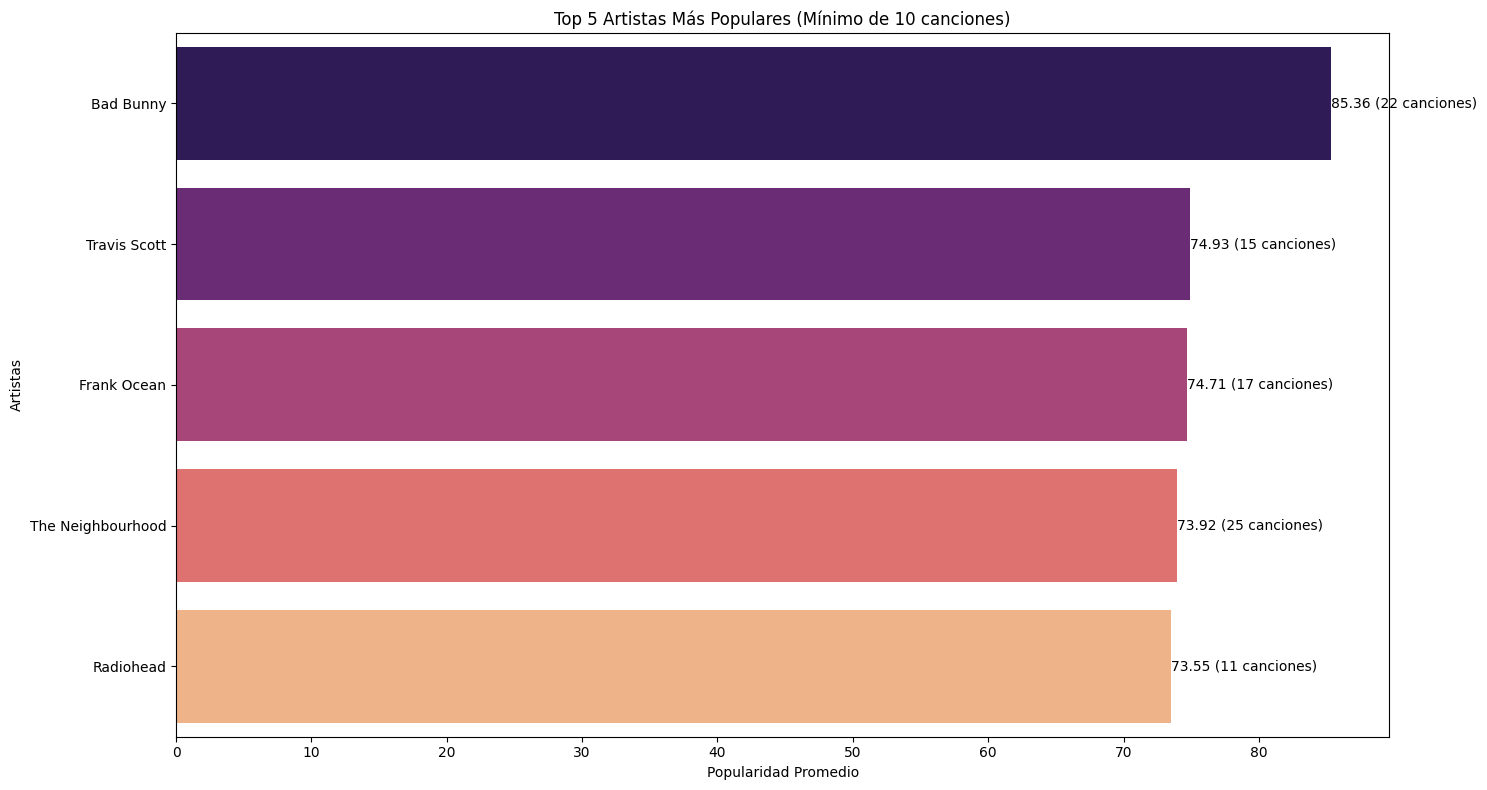

In [12]:
# Agrupación de artistas calculando el promedio de popularidad y la cantidad de canciones
artistas_stats = df.groupby('artists')['popularity'].agg(['mean', 'size']).reset_index()

# Filtrar para exigir un mínimo de 10 canciones
artistas_filtrados = artistas_stats[artistas_stats['size'] >= 10]

# Seleccionar los 5 artistas más populares bajo este criterio
artist_popularity_top5 = artistas_filtrados.sort_values(by='mean', ascending=False).head(5)

# Graficar los resultados
plt.figure(figsize=(15, 8))
sns.barplot(x='mean', y='artists', data=artist_popularity_top5, palette='magma', hue='artists', legend=False)

for index, row in artist_popularity_top5.reset_index(drop=True).iterrows():
    plt.text(row['mean'], index, f"{row['mean']:.2f} ({int(row['size'])} canciones)", color='black', ha='left', va='center')

plt.title('Top 5 Artistas Más Populares (Mínimo de 10 canciones)')
plt.xlabel('Popularidad Promedio')
plt.ylabel('Artistas')
plt.tight_layout()
plt.show()

**Objetivo:** identificar qué artistas concentran la mayor popularidad promedio, descartando artistas con pocas canciones que podrían distorsionar el promedio.

**Hallazgo:** Bad Bunny lidera con ~ 85,4, muy por encima del resto: Travis Scott (~ 74,9), Frank Ocean (~ 74,7), The Neighbourhood (~ 73,9) y Radiohead (~ 73,5).

**Implicancia:** el artista es un predictor potente de popularidad, pero tiene 31.437 valores únicos, así que no sirve codificarlo directamente en un modelo debido a su alta cardinalidad.

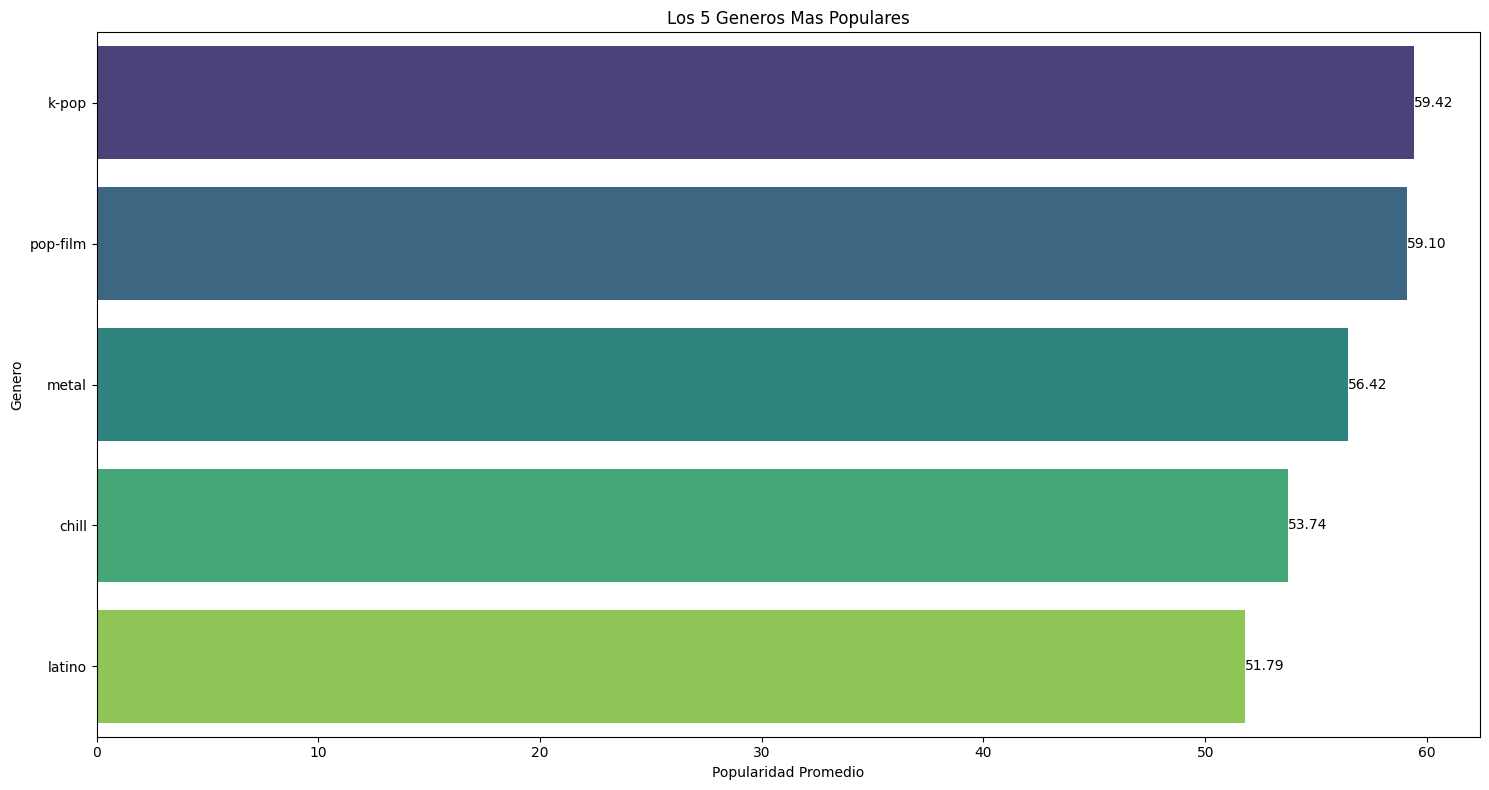

In [13]:
# Mostrar los generos mas populares
genre_popularity = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).reset_index()

# Mostrar solo los 5 generos mas populares.
genre_popularity_top5 = genre_popularity.head(5)

plt.figure(figsize=(15, 8))
sns.barplot(x='popularity', y='track_genre', data=genre_popularity_top5, palette='viridis', hue='track_genre', legend=False)

# Adicion de etiquetas que muestren el valor del Y sobre las barras.
for index, row in genre_popularity_top5.iterrows():
    plt.text(row.popularity, index, f'{row.popularity:.2f}', color='black', ha="left", va="center")

plt.title('Los 5 Generos Mas Populares')
plt.xlabel('Popularidad Promedio')
plt.ylabel('Genero')
plt.tight_layout()
plt.show()

In [14]:
print(df["track_genre"].nunique())

113


**Objetivo:** ver qué géneros tienen mejor popularidad promedio.

**Hallazgo:** k-pop (~ 59,4), pop-film (~ 59,1), metal (~ 56,4), chill (~ 53,7) y latino (~ 51,8).

**Implicancia:** el género influye en la popularidad y es una variable categórica manejable (113 valores), buena candidata para el modelo.

### 4.2. Impacto del Contenido Explícito en la Popularidad

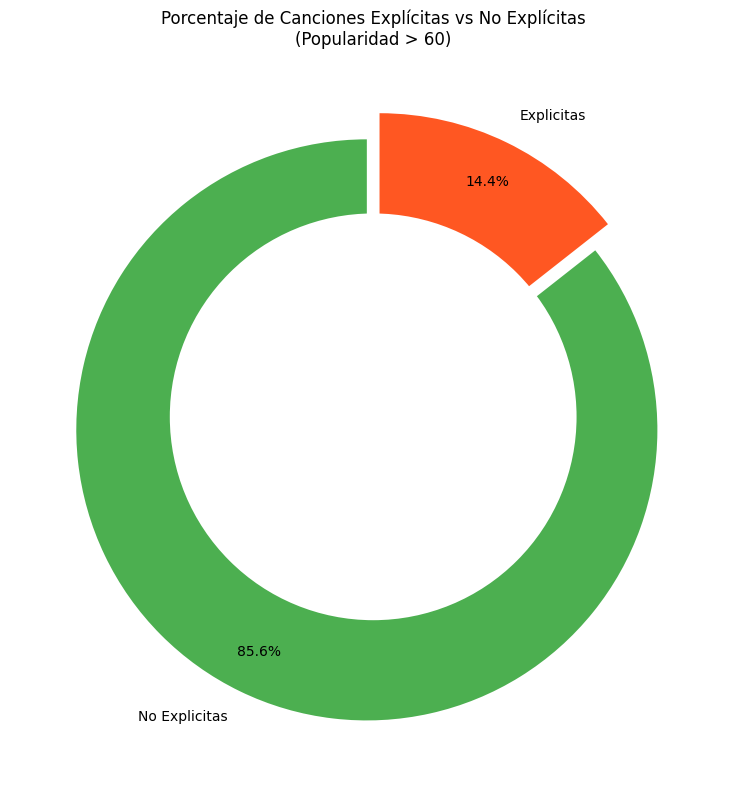

In [15]:
# Porcentaje de comparacion de canciones explicitas y no explicitas sobre el 60% de popularidad.

#Filtrado de canciones con popularidad mayor a 60
df_popular = df[df['popularity'] > 60]

# Contar las canciones explicitas
explicit_counts = df_popular['explicit'].value_counts()

# Configurar etiquetas y colores
labels = ['No Explicitas', 'Explicitas']
sizes = [explicit_counts.get(False, 0), explicit_counts.get(True, 0)]
colors = ['#4CAF50', '#FF5722']
explode = (0.05, 0.05)

# Crear el gráfico de rosquilla
plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, pctdistance=0.85)

centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Porcentaje de Canciones Explícitas vs No Explícitas\n(Popularidad > 60)')
plt.tight_layout()
plt.show()

In [16]:
porcentaje_explicitas_total = (df['explicit'].mean() * 100)
print(f"Porcentaje real de canciones explícitas en todo el catálogo deduplicado: {porcentaje_explicitas_total:.2f}%")

porcentaje_explicitas_popular = (df_popular['explicit'].mean() * 100)
print(f"Porcentaje real de canciones explícitas en el catálogo popular (>60): {porcentaje_explicitas_popular:.2f}%")

Porcentaje real de canciones explícitas en todo el catálogo deduplicado: 8.58%
Porcentaje real de canciones explícitas en el catálogo popular (>60): 14.40%


**Objetivo:** ver si el contenido explícito se asocia a mayor popularidad.

**Hallazgo:** entre las canciones con popularidad > 60, el 14,4% es explícita, contra el 8,6% del catálogo total.

**Implicancia:** `explicit` podría aportar al modelo, pero su uso tiene implicancias éticas.

### 4.3. Análisis de Correlación entre Variables Numéricas

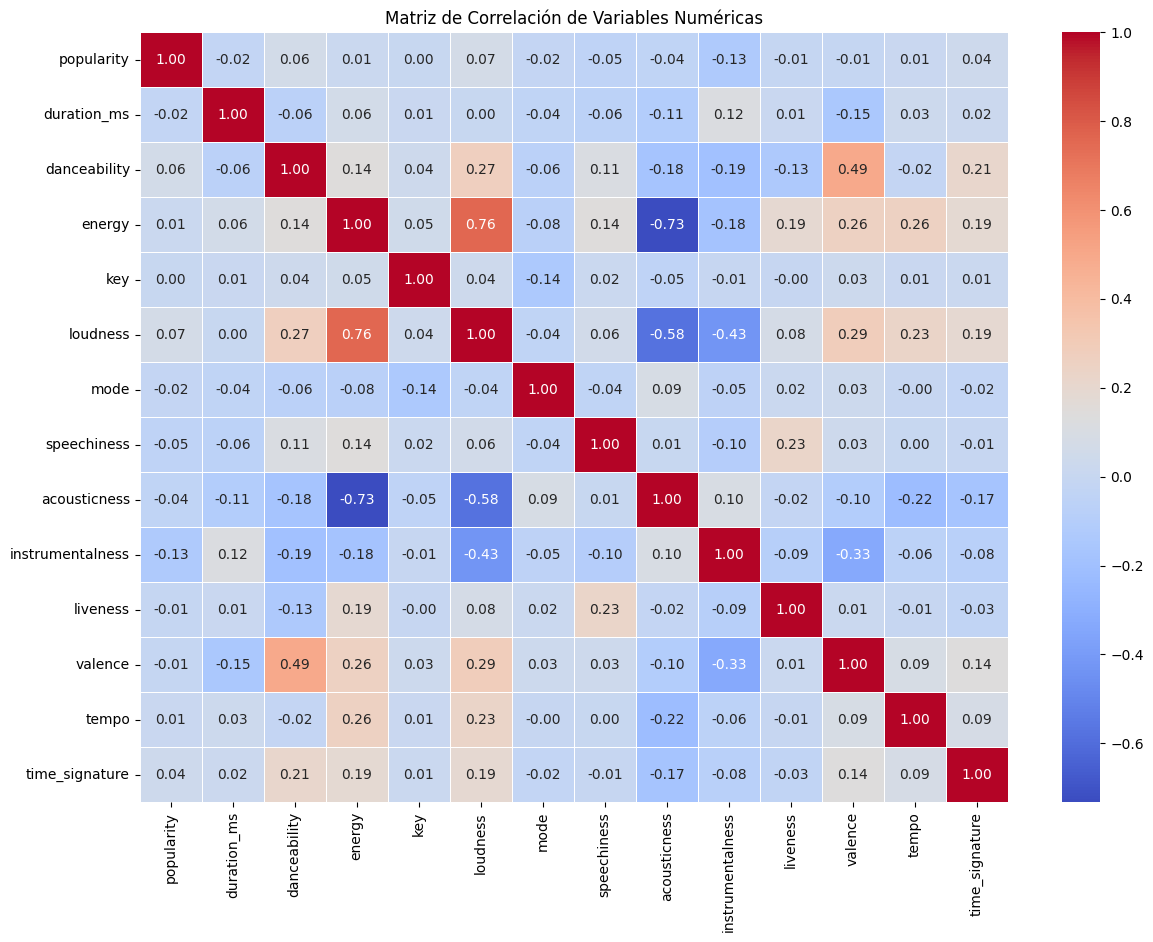

In [17]:
#Columnas Numericas
numerical_df = df.select_dtypes(include=[np.number])

# Eliminar la columna 'Unnamed: 0'
if 'Unnamed: 0' in numerical_df.columns:
    numerical_df = numerical_df.drop(columns=['Unnamed: 0'])

# Calcular la matriz de correlación
matriz_corr = numerical_df.corr()

# Visualizar
plt.figure(figsize=(14, 10))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

**Objetivo:** detectar relaciones lineales entre variables numéricas, tanto con la popularidad como entre ellas.

**Hallazgo:** ninguna variable correlaciona fuerte con la popularidad (la más alta en valor absoluto es instrumentalness, −0,13). En cambio, hay correlaciones altas entre predictores: energy–loudness (0,76) y energy–acousticness (0,73).

**Implicancia:** las características de audio por sí solas explican poco de la popularidad, así que no hay que esperar un modelo muy preciso.

### 4.4. Distribución de Popularidad en Géneros Extremos

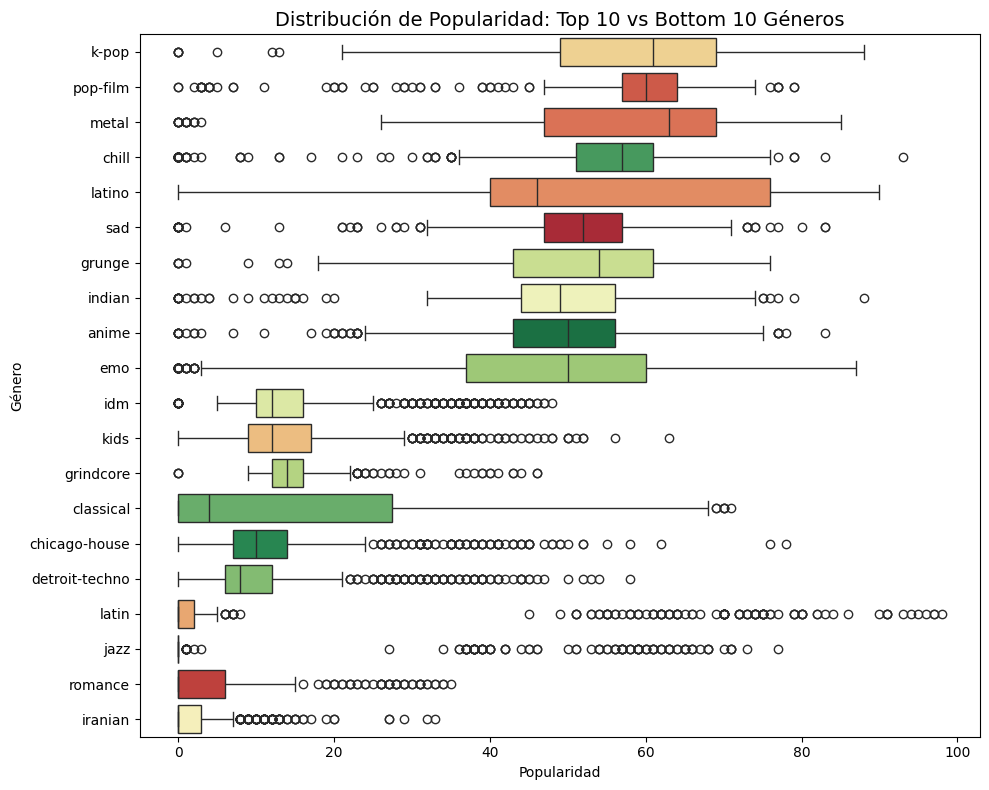

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 y bottom 10 géneros según popularidad promedio
promedio_por_genero = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False)
orden = list(promedio_por_genero.head(10).index) + list(promedio_por_genero.tail(10).index)
subconjunto = df[df['track_genre'].isin(orden)]

# Boxplot
plt.figure(figsize=(10, 8))
sns.boxplot(data=subconjunto, x='popularity', y='track_genre', order=orden,
            hue='track_genre', palette='RdYlGn_r', legend=False)
plt.title('Distribución de Popularidad: Top 10 vs Bottom 10 Géneros', fontsize=14)
plt.xlabel('Popularidad')
plt.ylabel('Género')
plt.tight_layout()
plt.show()

**Objetivo:** ver la dispersión de la popularidad dentro de cada género, no solo su media.

**Hallazgo:** los géneros altos (k-pop, pop-film) tienen medianas altas y dispersión moderada, mientras que en jazz, latin, romance e iranian la mediana es 0. Latino y metal muestran mucha dispersión.

**Implicancia:** la media sola engaña: un género puede tener media decente con medianas muy distintas. Además, esto anticipa el problema de los ceros que se analiza en 4.5.

### 4.5. Investigación de Canciones con Popularidad Cero por Género
Analizamos si la concentración de canciones con popularidad igual a 0 responde a géneros musicales específicos o si está distribuida de manera uniforme en el dataset.

In [19]:
# Calcular cuántas canciones tienen popularidad de 0 y su porcentaje en el total del dataframe
canciones_popularidad_cero = (df['popularity'] == 0).sum()
total_canciones = len(df)
porcentaje_cero = (canciones_popularidad_cero / total_canciones) * 100

print(f"Cantidad de canciones con popularidad igual a 0: {canciones_popularidad_cero}")
print(f"Porcentaje sobre el total del dataframe: {porcentaje_cero:.2f}%")

Cantidad de canciones con popularidad igual a 0: 9447
Porcentaje sobre el total del dataframe: 10.53%


,track_genre,total_canciones,canciones_con_cero,porcentaje_ceros
64,jazz,524,409,78.053435
59,iranian,988,648,65.587045
93,romance,904,555,61.393805
19,country,946,554,58.562368
67,latin,759,432,56.916996
90,rock,342,186,54.385965
102,soul,445,238,53.483146
3,alternative,407,197,48.402948
20,dance,948,452,47.679325
53,house,210,89,42.380952


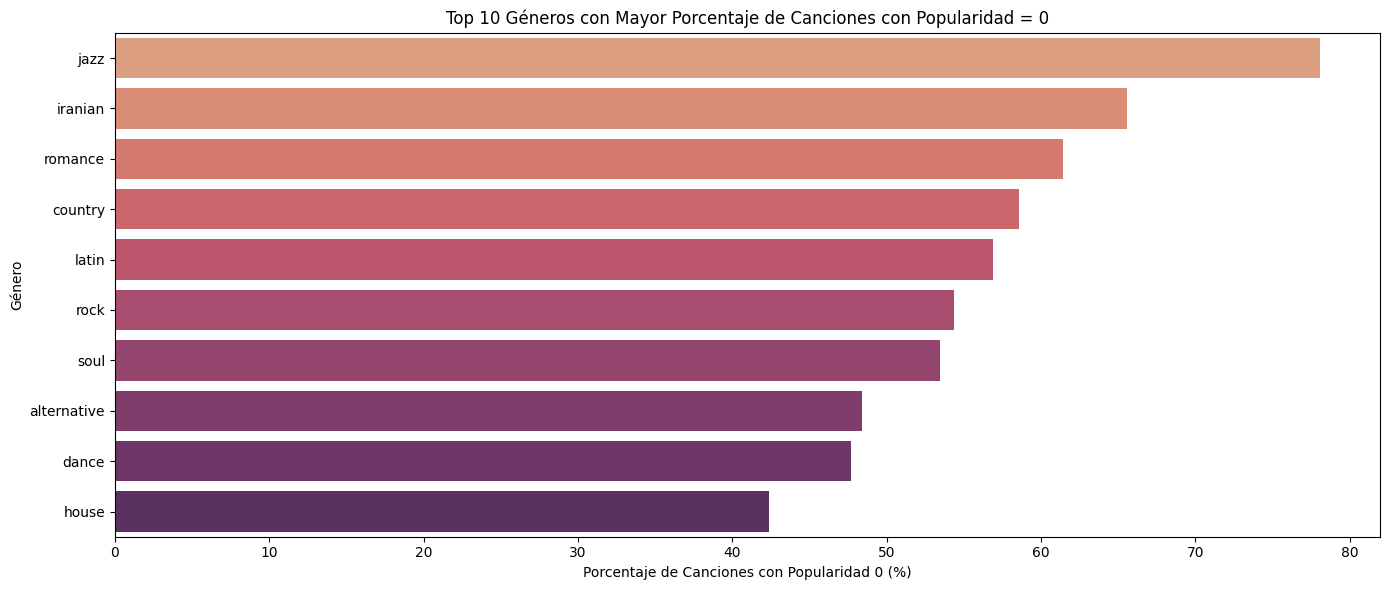

In [20]:
# Calcular el porcentaje y total de ceros por género
zeros_by_genre = df.groupby('track_genre')['popularity'].agg(
    total_canciones='count',
    canciones_con_cero=lambda x: (x == 0).sum(),
    porcentaje_ceros=lambda x: (x == 0).mean() * 100
).reset_index()

# Filtrar e inspeccionar los 10 géneros con mayor proporción de popularidad cero
top_zeros_genres = zeros_by_genre.sort_values(by='porcentaje_ceros', ascending=False).head(10)

display(top_zeros_genres)

# Graficar
plt.figure(figsize=(14, 6))
sns.barplot(x='porcentaje_ceros', y='track_genre', data=top_zeros_genres, palette='flare', hue='track_genre', legend=False)
plt.title('Top 10 Géneros con Mayor Porcentaje de Canciones con Popularidad = 0')
plt.xlabel('Porcentaje de Canciones con Popularidad 0 (%)')
plt.ylabel('Género')
plt.tight_layout()
plt.show()

Las canciones con popularidad cero no están distribuidas de manera uniforme. De hecho, se concentran fuertemente en géneros particulares.

No  representan "datos faltante" (como un valor nulo en la base de datos), sino más bien pistas inactivas en la plataforma dentro de esos nichos. Una posible hipotesis es que sean sonidos ambientales para estudiar y dormir; Pero el dataset no permite validarlo.

**Objetivo:** determinar si los ceros están repartidos al azar o concentrados.

**Hallazgo:** los ceros son ~10,5% del dataset y se concentran: jazz 78%, iranian 66%, romance 61%, country 59%, latin 57%.

**Implicancia:** no son datos faltantes sino un patrón por género; eliminarlos sesgaría el modelo contra esos géneros.

**Decición en torno a los valores 0** : Se ha decidido mantenerlos, ya que reflejan canciones reales. El modelo debe aprender que ciertos géneros tienden a 0.

### 4.6. Análisis de Relación entre Duración y Popularidad (Identificación de Outliers)

Para comprender mejor cómo influye la duración de una canción en su nivel de popularidad y detectar posibles outliers, analizaremos la duración en milisegundos frente a la popularidad y realizaremos una visualización de dispersión.

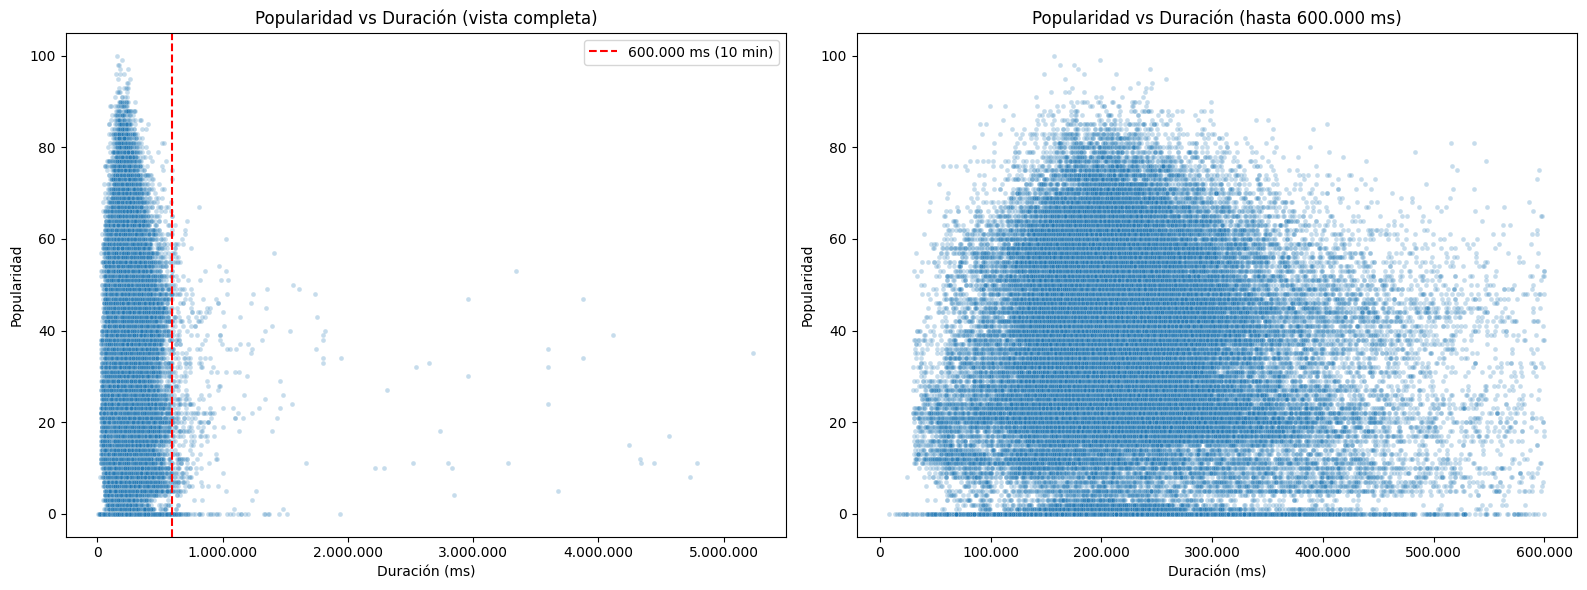

In [21]:
from matplotlib.ticker import FuncFormatter

fmt = FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", "."))  # 600.000

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Vista completa: se ven los outliers extremos
sns.scatterplot(data=df, x="duration_ms", y="popularity", alpha=0.25, s=12, ax=axes[0])
axes[0].axvline(600_000, color="red", linestyle="--", label="600.000 ms (10 min)")
axes[0].set_title("Popularidad vs Duración (vista completa)")
axes[0].set_xlabel("Duración (ms)")
axes[0].set_ylabel("Popularidad")
axes[0].xaxis.set_major_formatter(fmt)
axes[0].legend()

# Vista ampliada: hasta 600.000 ms, donde está la mayoría de canciones
sns.scatterplot(data=df[df["duration_ms"] <= 600_000], x="duration_ms", y="popularity",
                alpha=0.25, s=12, ax=axes[1])
axes[1].set_title("Popularidad vs Duración (hasta 600.000 ms)")
axes[1].set_xlabel("Duración (ms)")
axes[1].set_ylabel("Popularidad")
axes[1].xaxis.set_major_formatter(fmt)

plt.tight_layout()
plt.show()

In [22]:
q1, q3 = df["duration_ms"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Límites IQR: {lim_inf:,.0f} ms  a  {lim_sup:,.0f} ms")
print("Outliers por IQR:", ((df["duration_ms"] < lim_inf) | (df["duration_ms"] > lim_sup)).sum())

df.nlargest(5, "duration_ms")[["track_name", "artists", "track_genre", "duration_ms", "popularity"]]

Límites IQR: 36,160 ms  a  401,172 ms
Outliers por IQR: 4225


,track_name,artists,track_genre,duration_ms,popularity
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,minimal-techno,5237295,35
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,breakbeat,4789026,11
24348,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,detroit-techno,4730302,8
73840,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,minimal-techno,4563897,17
13344,House of Om - Mark Farina - Continuous Mix,Mark Farina,chicago-house,4447520,11


In [23]:
# Estadísticos de duración (en minutos solo para facilitar la lectura)
print(f"Mediana de duración: {df['duration_ms'].median() / 60000:.2f} min")
print(f"Duración máxima: {df['duration_ms'].max() / 60000:.2f} min")

# Popularidad promedio según grupo de duración
grupo = pd.cut(df["duration_ms"],
               bins=[0, 60_000, 600_000, df["duration_ms"].max()],
               labels=["< 1 min", "1 a 10 min", "> 10 min"])
print("\nPopularidad promedio por grupo de duración:")
print(df.groupby(grupo, observed=True)["popularity"].agg(["mean", "median", "size"]).round(2))

# Correlación lineal duración-popularidad
print(f"\nCorrelación duración-popularidad: {df['duration_ms'].corr(df['popularity']):.3f}")

# Qué géneros concentran los outliers largos
print("\nGéneros con más canciones > 10 min:")
print(df[df["duration_ms"] > 600_000]["track_genre"].value_counts().head(5))

Mediana de duración: 3.55 min
Duración máxima: 87.29 min

Popularidad promedio por grupo de duración:
              mean  median   size
duration_ms                      
< 1 min      21.94    20.0    790
1 a 10 min   33.36    34.0  88400
> 10 min     23.87    22.0    550

Correlación duración-popularidad: -0.023

Géneros con más canciones > 10 min:
track_genre
detroit-techno    58
iranian           51
new-age           40
classical         35
black-metal       35
Name: count, dtype: int64


**Objetivo:** detectar canciones con duración atípica y ver si afectan la popularidad.

**Hallazgo:** La duración mediana es ~ 3,55 min y el máximo ~ 87 min; hay 550 canciones de más de 10 min y 790 de menos de 1 min. La correlación lineal entre duración y popularidad es prácticamente nula (−0,02).

**Implicancia:** la duración no predice popularidad linealmente y los extremos son pocos; se conservan, vigilando su efecto en el modelo.

**Desición en torno a los outliers** : son pocos respecto del total (550 + 790 canciones de 89.740) y la duración casi no se relaciona con la popularidad (correlación de −0,023). Por lo que hemos decidio mantenerlos.

In [24]:
# Canciones entre el límite IQR y 10 min (las que el IQR excluiría pero el umbral de 10 min conserva)
medio = df[(df["duration_ms"] > lim_sup) & (df["duration_ms"] <= 600_000)]
print("Canciones entre el límite IQR y 10 min:", len(medio))
print(medio["track_genre"].value_counts().head(8))

# Qué hay realmente en las canciones de menos de 1 min
cortas = df[df["duration_ms"] <= 60_000]
print("\nGéneros con más canciones < 1 min:")
print(cortas["track_genre"].value_counts().head(8))
cortas.sample(8, random_state=1)[["track_name", "track_genre", "duration_ms"]]

Canciones entre el límite IQR y 10 min: 3574
track_genre
minimal-techno    324
detroit-techno    291
chicago-house     283
iranian           161
trance            161
black-metal       139
breakbeat         123
new-age           117
Name: count, dtype: int64

Géneros con más canciones < 1 min:
track_genre
grindcore     159
children       81
disney         79
classical      79
kids           57
show-tunes     34
idm            33
iranian        29
Name: count, dtype: int64


,track_name,track_genre,duration_ms
59443,Obsequious Supremacy,iranian,39682
16678,"6 Variations in F, K.54: 2. Variation I",classical,51223
26180,Ballada o Flegmisławie,disney,44360
42524,Strength In Your Conviction,grindcore,56200
14426,Puppy Dog Pals Main Title Theme,children,57789
14585,Add a Little Fancy (Fancy Nancy Main Title),children,53568
42395,Scatology Homework (Remix),grindcore,49453
42724,Tumorous Parenchyma of Red Corpuscles,grindcore,43468


**Justificación de umbrales**

**Por qué no usar el límite del IQR (~6,7 min):** el IQR marca 4.225 canciones como outliers, y 3.574 de ellas duran entre ese límite y 10 min. Ese tramo lo dominan géneros como minimal-techno, detroit-techno, chicago-house, trance y black-metal, donde las pistas largas son habituales, por lo que no son anomalías para el negocio.

**Límite inferior (< 1 min):** las 790 canciones bajo este umbral se concentran en grindcore, children, disney, classical y kids. La muestra revisada corresponde a canciones cortas propias de esos géneros (por ejemplo, temas principales de series infantiles o variaciones de música clásica), no a ruido o efectos.

**Límite superior (> 10 min):** las 550 canciones sobre este umbral incluyen mixes continuos de DJ (el top 5 lo muestra) y se concentran en detroit-techno, iranian, new-age, classical y black-metal.

Se usan 1 y 10 min como umbrales de referencia para identificar extremos por criterio de negocio. Ninguno de los dos grupos se elimina.

# 5. Dataset Final para Modelado

Resumen de las filas que quedan después de cada paso de preparación y guardado del dataset limpio.

In [25]:
resumen = pd.DataFrame({
    "Paso": [
        "Dataset original",
        "Tras eliminar registros con nulos (sección 3.1)",
        "Tras deduplicar por track_id (sección 3.2)",
        "Tras decisión sobre ceros de popularidad (sección 4.5)",
        "Tras decisión sobre outliers de duración (sección 4.6)",
    ],
    "Filas": [114_000, 113_999, 89_740, len(df), len(df)],
    "Observación": [
        "Valor de df.info() en la sección 2.1",
        "Se elimina 1 fila",
        "Se eliminan 24.259 track_id repetidos",
        "Se conservan todos",
        "Se conservan todos",
    ],
})
display(resumen)

df.to_csv("Spotify_Tracks_Dataset_limpio.csv", index=False)
print("Dataset guardado:", df.shape)

,Paso,Filas,Observación
0,Dataset original,114000,Valor de df.info() en la sección 2.1
1,Tras eliminar registros con nulos (sección 3.1),113999,Se elimina 1 fila
2,Tras deduplicar por track_id (sección 3.2),89740,Se eliminan 24.259 track_id repetidos
3,Tras decisión sobre ceros de popularidad (secc...,89740,Se conservan todos
4,Tras decisión sobre outliers de duración (secc...,89740,Se conservan todos


Dataset guardado: (89740, 20)


# 6. Evaluación de sesgos, ética y privacidad de los datos



### **6.1 Posibles sesgos**

**Sesgo de sobrerrepresentación:** El dataset original tenía 1.000 canciones por género (distribución artificial). Tras deduplicar, el rango pasa a estar entre 74 y 1.000 canciones por género y se pierde el género songwriter.

Aún así sigue siendo una distribución artificial, y no refleja el consumo real de spotify.

In [26]:
raw = pd.read_csv("../data/Spotify_Tracks_Dataset.csv")
print("Géneros originales:", raw["track_genre"].nunique())
print("Géneros tras deduplicar:", df["track_genre"].nunique())
print("Géneros que desaparecieron:", set(raw["track_genre"]) - set(df["track_genre"]))

orig = raw["track_genre"].value_counts()
dedup = df["track_genre"].value_counts()
print(f"Canciones por género (original): mín {orig.min()}, máx {orig.max()}")
print(f"Canciones por género (deduplicado): mín {dedup.min()}, máx {dedup.max()}")

Géneros originales: 114
Géneros tras deduplicar: 113
Géneros que desaparecieron: {'songwriter'}
Canciones por género (original): mín 1000, máx 1000
Canciones por género (deduplicado): mín 74, máx 1000


### 6.2 Consideraciones éticas

**Riesgo de retroalimentación algorítmica:** Predecir y promover solo lo “popular” puede reducir la diversidad musical.

**Falta de equidad con los artistas:** Spotify cuenta tanto con artistas respaldados por enormes sellos discográficos , como con artistas independientes. Por lo que si predecimos la popularidad sin ese contexto no hay forma de que un artista independiente pueda competir con los números de un artista ya consolidado.

**Usar la variable “Explicit” como predictor :** Considerar esa variable en decidir qué contenido promocionar podría incentivar contenido explícito solo para ganar visibilidad, sin considerar el impacto en audiencias sensibles.



### 6.3 Privacidad de los datos

El dataset no tiene datos de usuarios, la popularidad es una metrica agregada.

Si contiene nombres de artistas, que son datos personales de personas reales. Su uso se limita a fines academicos y no se elaboran perfiles individuales.

Marco normativo: Ley 19.628 y Ley 21.719 de proteccion de datos personales en Chile, y como referencia el GDPR (minimizacion y limitacion de la finalidad).

Uso comercial: habria que revisar los terminos de uso de la API de Spotify.

# 7. Comparación de Modelados Supervisados
**Problema:** clasificación binaria. Se predice si una canción es popular o no, a partir de sus características de audio, estructura, título y género. **(Se parte del dataset limpio de la sección 5)** . Se comparan un árbol de decisión y un random forest, con solo variables de audio y con variables ampliadas, frente a una línea base.


### 7.1 variables

Se construyen 134 variables en 4 grupos:

**audio** (11)

**estructura** (3: duración, tonalidad, compás)

**título y colaboración** (7: nº de artistas, banderas de remix/live/remaster/feat, largo del título y si es single)

**género** (113 columnas 0/1).

In [27]:
RUTA_CSV = "Spotify_Tracks_Dataset_limpio.csv"   # ajustar

import pandas as pd
import numpy as np

audio = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo", "explicit", "mode"]

# una columna por género (1 si es el género de la canción)
orig = pd.read_csv(RUTA_CSV).dropna(subset=["artists", "album_name", "track_name"])
generos = pd.crosstab(orig["track_id"], orig["track_genre"]).clip(upper=1)
generos.columns = ["g_" + c for c in generos.columns]

d = df.set_index("track_id").join(generos)
d["is_popular"] = (d["popularity"] >= 60).astype(int) #definimos popularity minimo como 60
d["explicit"] = d["explicit"].astype(int)

# Rasgos del título y de la colaboración
d["n_artistas"] = d["artists"].str.count(";") + 1
t = d["track_name"].str.lower()
d["flag_remix"] = t.str.contains("remix|mix|edit").astype(int)
d["flag_live"] = t.str.contains("live|ao vivo|en vivo").astype(int)
d["flag_remaster"] = t.str.contains("remaster|version|versión|deluxe").astype(int)
d["flag_feat"] = t.str.contains("feat|with ").astype(int)
d["len_titulo"] = d["track_name"].str.len()
d["es_single"] = (d["album_name"].str.lower() == t).astype(int)

grupos_vars = {
    "Audio": audio,
    "Estructura": ["duration_ms", "key", "time_signature"],
    "Título y colaboración": ["n_artistas", "flag_remix", "flag_live", "flag_remaster",
                              "flag_feat", "len_titulo", "es_single"],
    "Género": list(generos.columns),
}
cols_todas = sum(grupos_vars.values(), [])
print("Variables totales:", len(cols_todas))

Variables totales: 134


### 7.2 división por artista y balanceo

**División:** 80% entrenamiento y 20% prueba (19.004 canciones en el test), agrupando por **artista principal** para que ningún artista aparezca en ambos conjuntos. Además se **eliminan del entrenamiento** las canciones donde cualquier artista (incluidos invitados) aparece en el test: 12.630 filas descartadas.

**Balanceo:** solo en entrenamiento y por **submuestreo aleatorio** de la clase mayoritaria (no populares), sin repetir filas ni crear datos sintéticos. Quedan 5.555 canciones por clase (11.110 en total), lo que descarta unas 47.000 canciones no populares (~81% del entrenamiento tras la purga).

**Datos eliminados antes del modelado (sección 3):** 1 fila con nulos y 24.259 registros duplicados por `track_id`, quedando 89.740 canciones únicas. Se conservaron los ceros de popularidad y los outliers de duración.

El **conjunto de prueba no se modifica** y conserva la proporción real: ~90% no populares y ~10% populares (popularidad ≥ 60).

In [28]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils import resample

# Lista de artistas por canción y artista principal (el primero)
lista = d["artists"].str.split(";").apply(lambda l: [a.strip() for a in l])
d["artista_principal"] = lista.str[0]

X, y = d[cols_todas], d["is_popular"]

# split agrupado por artista principal
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
              .split(X, y, d["artista_principal"]))

# quitar del train canciones con cualquier artista que esté en test
artistas_test = {a for l in lista.iloc[te] for a in l}
sin_fuga = ~lista.iloc[tr].apply(lambda l: any(a in artistas_test for a in l)).values
print(f"Filas de train descartadas por compartir artista con test: {(~sin_fuga).sum()}")
tr = tr[sin_fuga]

X_test, y_test = X.iloc[te], y.iloc[te]

# Balanceo solo en entrenamiento; el test conserva la proporción real
train = X.iloc[tr].assign(is_popular=y.iloc[tr])
n = train["is_popular"].value_counts().min()
train_bal = pd.concat([resample(train[train["is_popular"] == c], replace=False,
                                n_samples=n, random_state=42) for c in (0, 1)])
X_train, y_train = train_bal[cols_todas], train_bal["is_popular"]
g_train = d["artista_principal"].loc[X_train.index]

print("Train:", X_train.shape, "| Test:", X_test.shape)

Filas de train descartadas por compartir artista con test: 12630
Train: (11110, 134) | Test: (19004, 134)


### 7.3 elegir hiperparámetros (≈3 min)

Se elige la profundidad máxima de cada modelo con validación cruzada de 3 folds **agrupada por artista**, usando solo el entrenamiento y el F1 como criterio. La grilla se limitó para mantener la ejecución en torno a 3 minutos.


In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

cv = GroupKFold(n_splits=3) #Agrupación de folds
nuevo_arbol = lambda p: DecisionTreeClassifier(max_depth=p, random_state=42)
nuevo_bosque = lambda p: RandomForestClassifier(n_estimators=100, max_depth=p,
                                                min_samples_leaf=10, random_state=42, n_jobs=-1)

def elegir_profundidad(crear_modelo, profundidades, cols):
    puntajes = {}
    for p in profundidades:
        puntajes[p] = cross_val_score(crear_modelo(p), X_train[cols], y_train,
                                      cv=cv, groups=g_train, scoring="f1").mean()
        print(f"   max_depth={p}: F1 de validación = {puntajes[p]:.3f}")
    return max(puntajes, key=puntajes.get)

print("Árbol - solo audio");   prof_arbol_a  = elegir_profundidad(nuevo_arbol,  [4, 6, 8, 10, 12], audio)
print("Árbol - ampliado");     prof_arbol_x  = elegir_profundidad(nuevo_arbol,  [6, 8, 10, 12, 16], cols_todas)
print("Bosque - solo audio");  prof_bosque_a = elegir_profundidad(nuevo_bosque, [8, 12, 16], audio)
print("Bosque - ampliado");    prof_bosque_x = elegir_profundidad(nuevo_bosque, [12, 16, 20], cols_todas)

Árbol - solo audio
   max_depth=4: F1 de validación = 0.661
   max_depth=6: F1 de validación = 0.657
   max_depth=8: F1 de validación = 0.649
   max_depth=10: F1 de validación = 0.634
   max_depth=12: F1 de validación = 0.620
Árbol - ampliado
   max_depth=6: F1 de validación = 0.579
   max_depth=8: F1 de validación = 0.616
   max_depth=10: F1 de validación = 0.591
   max_depth=12: F1 de validación = 0.602
   max_depth=16: F1 de validación = 0.663
Bosque - solo audio
   max_depth=8: F1 de validación = 0.667
   max_depth=12: F1 de validación = 0.661
   max_depth=16: F1 de validación = 0.654
Bosque - ampliado
   max_depth=12: F1 de validación = 0.730
   max_depth=16: F1 de validación = 0.735
   max_depth=20: F1 de validación = 0.737


### 7.4 entrenar y comparar

Se entrenan 5 modelos:

línea base (siempre predice la clase mayoritaria), árbol y bosque con solo audio, y árbol y bosque con variables ampliadas.


In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

resultados, probs, modelos = [], {}, {}

def evaluar(nombre, modelo, cols):
    modelo.fit(X_train[cols], y_train)
    prob = modelo.predict_proba(X_test[cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    probs[nombre], modelos[nombre] = prob, modelo
    resultados.append({"Modelo": nombre,
                       "Accuracy": accuracy_score(y_test, pred),
                       "Precisión": precision_score(y_test, pred, zero_division=0),
                       "Recall": recall_score(y_test, pred),
                       "F1": f1_score(y_test, pred),
                       "AUC": roc_auc_score(y_test, prob),
                       "Tasa FP": fp / (fp + tn),
                       "Accuracy train": accuracy_score(y_train, modelo.predict(X_train[cols]))})

evaluar("Línea base",          DummyClassifier(strategy="most_frequent"), audio)
evaluar("Árbol - solo audio",  nuevo_arbol(prof_arbol_a),   audio)
evaluar("Bosque - solo audio", nuevo_bosque(prof_bosque_a), audio)
evaluar("Árbol - ampliado",    nuevo_arbol(prof_arbol_x),   cols_todas)
evaluar("Bosque - ampliado",   nuevo_bosque(prof_bosque_x), cols_todas)

comparacion = pd.DataFrame(resultados).set_index("Modelo").round(3)
display(comparacion)

,Accuracy,Precisión,Recall,F1,AUC,Tasa FP,Accuracy train
Modelo,,,,,,,
Línea base,0.898,0.000,0.000,0.000,0.500,0.000,0.500
Árbol - solo audio,0.511,0.141,0.739,0.237,0.631,0.515,0.621
Bosque - solo audio,0.508,0.146,0.784,0.246,0.685,0.523,0.685
Árbol - ampliado,0.791,0.241,0.485,0.322,0.691,0.174,0.771
Bosque - ampliado,0.687,0.220,0.805,0.345,0.817,0.326,0.784


### ¿Qué nos dicen estas métricas?

**Accuracy:** El acurracy de la linea base es muy alta en comparación a los demás modelos. Esto debido a que dice “no popular” para todas las canciones y acierta el 90% porque ~90% de las canciones no lo son. Dentro de los otros modelos destaca el arbol ampliado, con un 0.791.

**Precisión:** baja en todos los modelos (0,14–0,24) porque solo ~ 10% de las canciones son populares; aun así supera al azar (~ 10%). Se usó el umbral estándar de 0,5 sin ajustarlo. Subirlo aumentaría la precisión, a costa de recomendar menos canciones y encontrar menos éxitos (menor recall).

**Recall:** El bosque ampliado encuentra ~8 de cada 10 canciones populares; el árbol ampliado, menos de la mitad (0,485).

**F1:** Bajo en todos porque la precisión limita el resultado.

**AUC:** El bosque ampliado ordena mejor con 0,817. Con solo audio el AUC baja a 0,63–0,69, así que género y metadatos mejoran la predicción.

**Tasa fp (falsos positivos):** el bosque ampliado marca por error 1 de cada 3 canciones no populares (0,326), y el árbol ampliado 0,174. Con umbral 0,5 ninguno cumple el KPI de ≤ 15%.

**Acuraccy Train:** No es comparable con la accuracy del test, porque el entrenamiento está balanceado 50/50 y el test no (~90/10). No permite concluir sobreajuste por sí sola.

**Gráfico de barras de los cuatro modelos. La línea punteada es la accuracy de la línea base.**


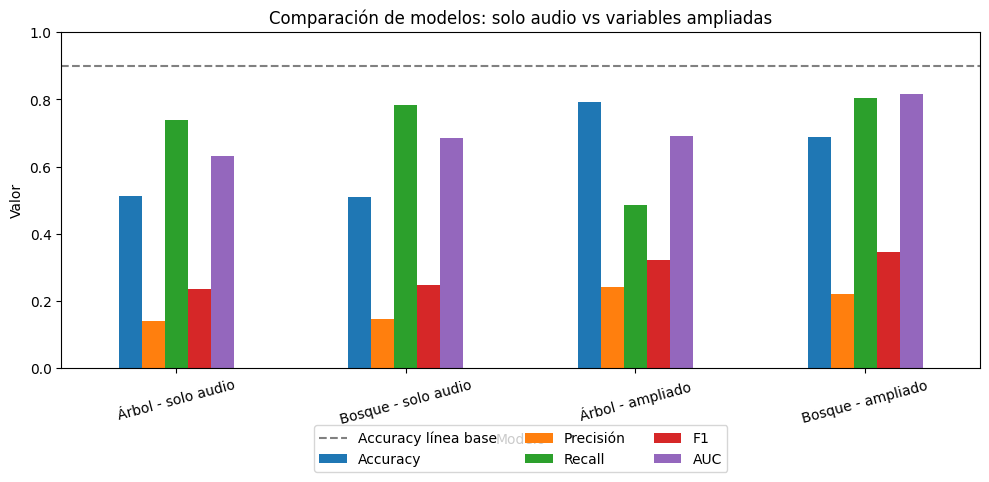

In [31]:
modelos_graf = ["Árbol - solo audio", "Bosque - solo audio", "Árbol - ampliado", "Bosque - ampliado"] #Esta var se usa tmbn para la matriz de confusion
metricas = ["Accuracy", "Precisión", "Recall", "F1", "AUC"]
ax = comparacion.loc[modelos_graf, metricas].plot(kind="bar", figsize=(10, 5), rot=15)
ax.axhline(comparacion.loc["Línea base", "Accuracy"], color="gray", linestyle="--", label="Accuracy línea base")
ax.set_ylim(0, 1)
ax.set_ylabel("Valor")
ax.set_title("Comparación de modelos: solo audio vs variables ampliadas")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

### 7.5 qué grupo de variables aporta más

Importancia por permutación: se desordenan todas las columnas de un grupo a la vez en el test y se mide la caída del AUC del bosque ampliado (promedio de 3 repeticiones). Mayor caída indica que el grupo aporta más. Al ser una medida sobre grupos completos, no entrega la importancia de variables individuales.


In [32]:
modelo_rf = modelos["Bosque - ampliado"]
rng = np.random.RandomState(42)
auc_base = roc_auc_score(y_test, modelo_rf.predict_proba(X_test[cols_todas])[:, 1])

filas = []
for nombre, cols in grupos_vars.items():
    caidas = []
    for _ in range(3):
        Xp = X_test[cols_todas].copy()
        Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]   # desordena el grupo completo
        caidas.append(auc_base - roc_auc_score(y_test, modelo_rf.predict_proba(Xp)[:, 1]))
    filas.append({"Grupo de variables": nombre, "Caída del AUC": np.mean(caidas)})

imp_grupos = pd.DataFrame(filas).sort_values("Caída del AUC", ascending=False).round(3)
display(pd.DataFrame(filas).sort_values("Caída del AUC", ascending=False).round(3))

,Grupo de variables,Caída del AUC
3,Género,0.148
0,Audio,0.101
2,Título y colaboración,0.034
1,Estructura,0.009


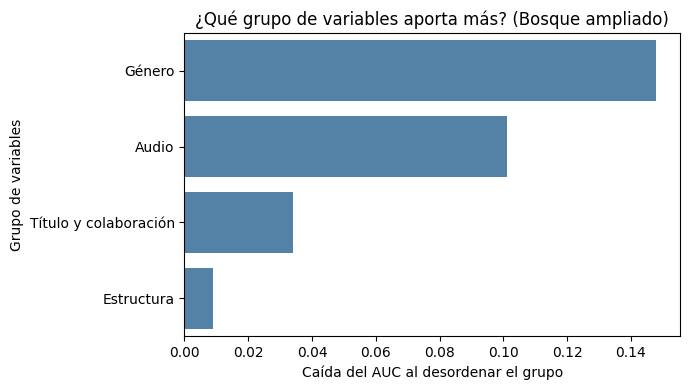

In [33]:
plt.figure(figsize=(7, 4))
sns.barplot(data=imp_grupos, x="Caída del AUC", y="Grupo de variables", color="steelblue")
plt.title("¿Qué grupo de variables aporta más? (Bosque ampliado)")
plt.xlabel("Caída del AUC al desordenar el grupo")
plt.tight_layout()
plt.show()

### 7.6 matrices de confusión

Aciertos y errores (falsos positivos y falsos negativos) de los cuatro modelos en el test, con artistas no vistos.


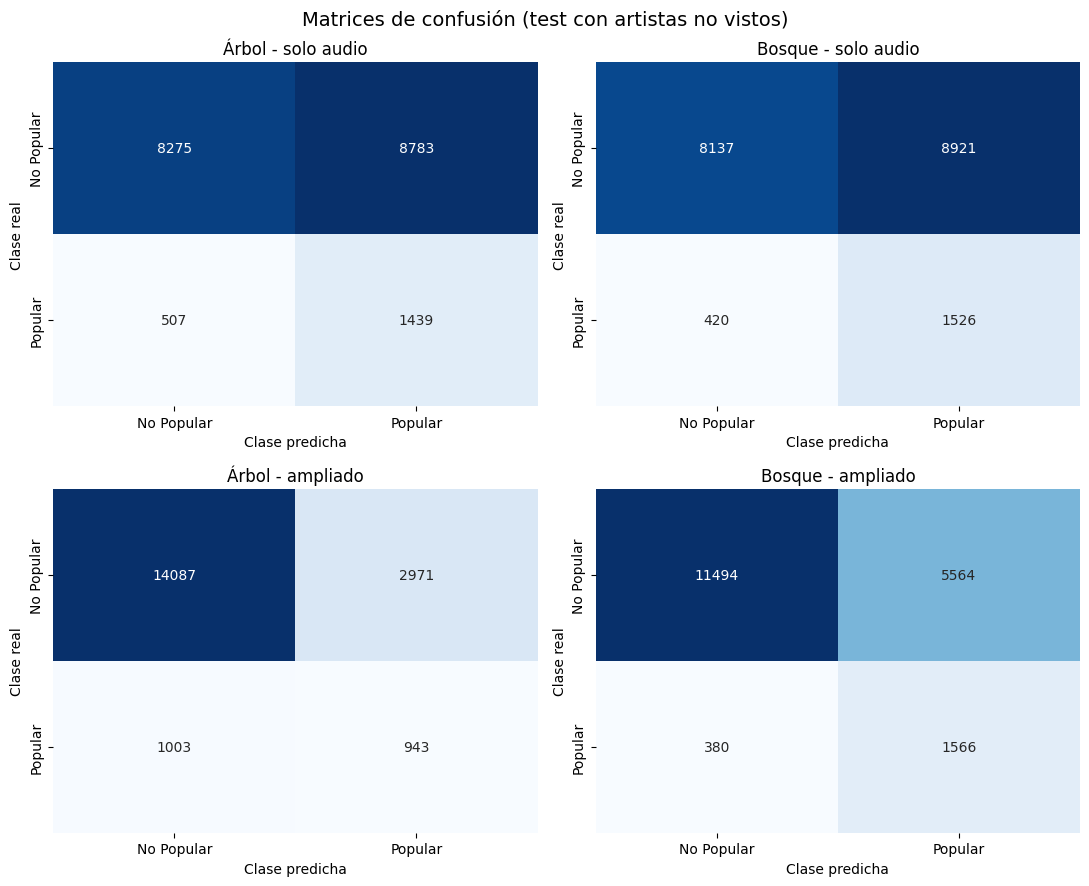

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, nombre in zip(axes.ravel(), modelos_graf):
    pred = (probs[nombre] >= 0.5).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Popular", "Popular"], yticklabels=["No Popular", "Popular"])
    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión (test con artistas no vistos)", fontsize=14)
plt.tight_layout()
plt.show()

### 7.7 CONCLUSIONES DE LA COMPARACIÓN DE MODELOS SUPERVISADOS

Los modelos tienen un desempeño moderado. Con umbral 0,5 su precisión (0,14–0,24) no alcanza la meta de 40% y la tasa de falsos positivos (0,326 en el bosque ampliado y 0,174 en el árbol ampliado) tampoco cumple la meta de ≤ 15%. Aun así, la precisión supera la tasa base de canciones populares (~10%) y el AUC del bosque ampliado (0,82) muestra que ordena razonablemente las canciones.

En el bosque ampliado, el género es el grupo de variables que más aporta a la predicción (caída del AUC de 0,148), seguido por las variables de audio (0,101); esto no implica que el género cause la popularidad. **En conjunto, el modelo sirve como filtro auxiliar para priorizar canciones, no como único criterio de inversión.**

El bosque ampliado obtuvo el mejor AUC, F1 y recall; el árbol ampliado logró mayor precisión y menos falsos positivos con ese umbral, además de ser interpretable. Se prefiere el bosque ampliado por su mejor capacidad para ordenar y encontrar canciones populares.

# 8. Modelo No Supervisado: Segmentación de Canciones con K-Means

**Objetivo:** agrupar las canciones según su perfil de audio, sin usar la popularidad ni el género, para ver si existen "tipos" de canciones y si esos tipos se relacionan con la popularidad.

A diferencia de la sección 7, **aquí no hay variable objetivo**: el modelo solo busca canciones parecidas entre sí.

### 8.1 Variables y estandarización
Se usan las 9 variables continuas de audio, estandarizadas para que ninguna pese más por su escala. Se excluyen `explicit`, `mode`, `key` y `time_signature` (binarias o categóricas) y `duration_ms` (outliers extremos).
La popularidad y el género **no participan** en el clustering; se usan después solo para interpretar los grupos.


In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

vars_km = ["danceability", "energy", "loudness", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence", "tempo"]
X_km = StandardScaler().fit_transform(df[vars_km])
print("Matriz para clustering:", X_km.shape)

Matriz para clustering: (89740, 9)


### 8.2 Elección del número de clusters (k)

Se prueban valores de k entre 2 y 8. El **método del codo** busca el punto donde agregar clusters deja de reducir mucho la inercia (dispersión dentro de los grupos). El **coeficiente de silueta** (de -1 a 1) mide qué tan bien separados están los grupos; se calcula sobre una muestra de 10.000 canciones para acortar el tiempo.

**Decisión: k = 4.** La inercia baja gradualmente, sin un codo claro. La silueta más alta es la de k = 2 (≈ 0,26), pero solo separaría canciones calmas de intensas. Con k = 4 la silueta es ≈ 0,17 y los grupos son claramente interpretables. Como la silueta es baja en todos los casos (< 0,3), los grupos se **solapan** y no son categorías nítidas.

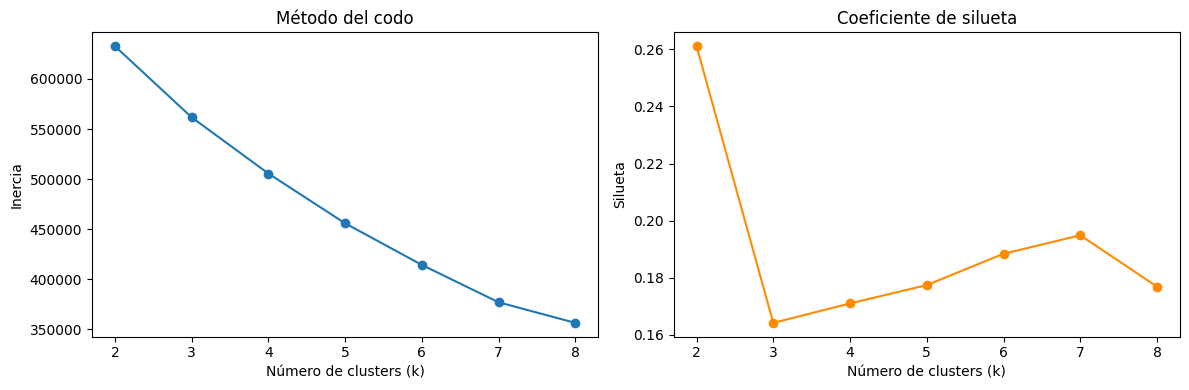

{2: np.float64(0.261), 3: np.float64(0.164), 4: np.float64(0.171), 5: np.float64(0.177), 6: np.float64(0.188), 7: np.float64(0.195), 8: np.float64(0.177)}


In [36]:
muestra = np.random.RandomState(42).choice(len(X_km), 10000, replace=False)
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_km)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_km[muestra], km.labels_[muestra]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercia, marker="o")
ax[0].set(title="Método del codo", xlabel="Número de clusters (k)", ylabel="Inercia")
ax[1].plot(ks, silueta, marker="o", color="darkorange")
ax[1].set(title="Coeficiente de silueta", xlabel="Número de clusters (k)", ylabel="Silueta")
plt.tight_layout()
plt.show()

print({k: round(s, 3) for k, s in zip(ks, silueta)})

### 8.3 Entrenamiento del modelo

K-Means forma 4 grupos ubicando centros y asignando cada canción al más cercano. Los tamaños son desiguales: 36.646, 27.445, 18.648 y 7.001 canciones.

In [37]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_km)
df_km = df.copy()
df_km["cluster"] = kmeans.labels_
print(df_km["cluster"].value_counts().sort_index())

cluster
0    18648
1     7001
2    36646
3    27445
Name: count, dtype: int64


### 8.4 Visualización en 2 dimensiones (PCA)
PCA resume las 9 variables en 2 componentes para poder graficarlas. Es solo una vista aproximada: conserva alrededor de la mitad de la información, por lo que la superposición visual de los grupos no implica que estén mal formados.

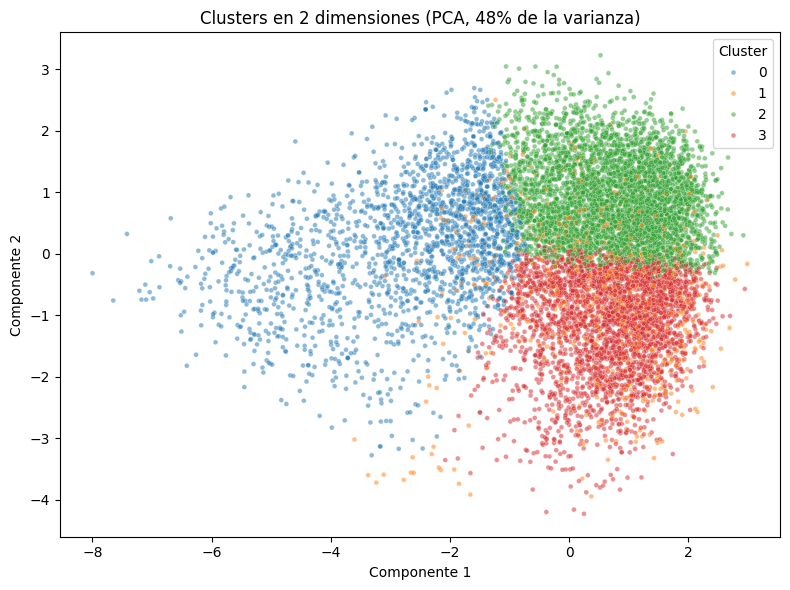

In [38]:
pca = PCA(n_components=2, random_state=42).fit(X_km)
coords = pca.transform(X_km[muestra])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df_km["cluster"].values[muestra],
                palette="tab10", s=12, alpha=0.5)
plt.title(f"Clusters en 2 dimensiones (PCA, {pca.explained_variance_ratio_.sum():.0%} de la varianza)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### 8.5 Popularidad en cada cluster
Primero se promedia cada variable de audio por cluster para describir cómo suena cada grupo. Luego se usa la popularidad, que **no** participó en el clustering, para ver si los grupos se relacionan con ella.

In [39]:
perfil_audio = df_km.groupby("cluster")[vars_km].mean().round(2)
display(perfil_audio)

df_km["popular_60"] = df_km["popularity"] >= 60
resumen = df_km.groupby("cluster").agg(
    canciones=("track_id", "size"),
    popularidad_media=("popularity", "mean"),
    pct_popular_60=("popular_60", "mean"),
    pct_popularidad_0=("popularity", lambda s: (s == 0).mean()),
    pct_explicit=("explicit", "mean"))
cols_pct = ["pct_popular_60", "pct_popularidad_0", "pct_explicit"]
resumen[cols_pct] = resumen[cols_pct] * 100
display(resumen.round(1))

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.44,0.26,-15.22,0.05,0.78,0.36,0.16,0.28,108.77
1,0.53,0.74,-7.85,0.21,0.37,0.08,0.74,0.49,119.83
2,0.69,0.68,-7.04,0.09,0.28,0.06,0.16,0.67,118.60
3,0.48,0.80,-6.04,0.08,0.08,0.23,0.19,0.33,136.27


,canciones,popularidad_media,pct_popular_60,pct_popularidad_0,pct_explicit
cluster,,,,,
0,18648,30.4,8.2,14.5,1.4
1,7001,33.4,5.3,5.4,14.4
2,36646,34.2,13.8,12.0,11.0
3,27445,33.7,10.3,7.3,8.8


### 8.6 Géneros dominantes en cada cluster
El género tampoco participó en el clustering; se usa solo para comprobar si los grupos tienen sentido musical.

In [40]:
for c in range(K):
    top = df_km[df_km["cluster"] == c]["track_genre"].value_counts(normalize=True).head(4) * 100
    print(f"Cluster {c}: " + ", ".join(f"{g} ({p:.1f}%)" for g, p in top.items()))

Cluster 0: ambient (4.7%), new-age (4.6%), sleep (4.3%), classical (4.2%)
Cluster 1: comedy (11.8%), pagode (6.5%), sertanejo (4.7%), samba (3.8%)
Cluster 2: salsa (2.4%), kids (2.3%), dancehall (2.3%), forro (2.1%)
Cluster 3: black-metal (3.3%), grindcore (3.3%), death-metal (3.1%), drum-and-bass (2.9%)


### 8.7 Conclusiones del modelo no supervisado

| Grupo | Perfil de audio | Géneros dominantes | Canciones | Popularidad ≥ 60 | Popularidad 0 |
|---|---|---|---|---|---|
| **Calmas y acústicas** (cluster 0) | Energía baja (0,26), muy acústicas (0,78), volumen bajo (-15 dB) | ambient, new-age, sleep, classical | 18.648 | 8,2% | 14,5% |
| **En vivo y habladas** (cluster 1) | Mucha presencia de público (liveness 0,74) y de habla (0,21) | comedy, pagode, sertanejo, samba | 7.001 | 5,3% | 5,4% |
| **Bailables y alegres** (cluster 2) | Danceability alta (0,69) y valence alta (0,67) | salsa, kids, dancehall, forro | 36.646 | 13,8% | 12,0% |
| **Intensas y rápidas** (cluster 3) | Energía alta (0,80), tempo alto (136 BPM), casi nada acústicas (0,08) | black-metal, grindcore, death-metal, drum-and-bass | 27.445 | 10,3% | 7,3% |

El audio por sí solo separa "tipos" de canciones coherentes: cada grupo está dominado por familias de géneros reconocibles, sin que el modelo haya visto el género.

Los clusters se relacionan **débilmente** con la popularidad: la media va de 30 a 34 y la proporción de canciones ≥ 60 va de 5,3% a 13,8%. Esto es coherente con las correlaciones débiles de 4.3 y con el bajo aporte del audio solo en la sección 7.

Los ceros de popularidad se concentran en el grupo de música calma (14,5%), consistente con la hipótesis de la sección 4.5 sobre música ambiental, aunque el dataset no permite validarla.

**Aplicación:** la segmentación sirve para describir el catálogo y comparar candidatos dentro de un mismo perfil sonoro, no para predecir éxito.

**Limitaciones:** la silueta es baja (los grupos se solapan); el resultado depende de las variables y del k elegidos; y K-Means asume grupos de forma redondeada. Los porcentajes son descriptivos y no demuestran causalidad.